# So sánh Incremental DBSCAN với các thuật toán dựa trên mật độ

Notebook trình bày hai mặt của thí nghiệm: **Silhouette tự cài** để đánh giá chất lượng cụm và **thời gian cập nhật** để so sánh incremental với fit lại.

> Để xem thuật toán chạy từng bước, mở [Incremental_DBSCAN_Demo.ipynb](Incremental_DBSCAN_Demo.ipynb), mục 5.1 (insert/Merge) và 5.2 (delete/Split).

## Phạm vi so sánh

- Scikit-learn không cung cấp `IncrementalDBSCAN` hay `partial_fit` cho DBSCAN. Vì vậy sklearn DBSCAN ở đây là mốc **fit lại toàn bộ sau mỗi thay đổi**. Xem [API DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html).
- Chất lượng cụm được đánh giá chủ yếu bằng Silhouette tự cài trong `src/evaluation/metrics.py`; noise bị bỏ khỏi phép tính và báo riêng.
- ARI trong các file kết quả benchmark chỉ là đối chứng kỹ thuật về đồng thuận nhãn với bản OOP, không dùng để xếp hạng chất lượng HDBSCAN/OPTICS.
- OPTICS dùng cách trích cụm DBSCAN tại cùng `eps`; HDBSCAN giữ cơ chế phân cấp và tham số riêng.


## 1. Thiết kế thí nghiệm

- Dùng một luồng thẻ mô phỏng: D0 có 500 điểm, sau đó phát lại 20 cập nhật đầu (10 insert, 10 delete).
- Mỗi cấu hình chạy 5 lượt, cùng thứ tự cập nhật và cùng khoảng cách Euclidean.
- 2D dùng `log10_amount_vnd`, `hour_of_day`; 3D và 4D lần lượt thêm `distance_from_home_km` và `txns_last_7d`.
- Các chiều là các tập đặc trưng lồng nhau của cùng một luồng, không phải ba bộ dữ liệu độc lập.
- Chuẩn hóa dùng hằng số cố định trong `params.json`, tính trên toàn bộ luồng mô phỏng chứ không chỉ D0. Mọi thuật toán dùng cùng tọa độ. Vì hằng số có dùng cả các cập nhật tương lai, đây là so sánh có kiểm soát, chưa phải mô phỏng online không rò rỉ dữ liệu.

### Cấu hình

| Phương pháp | Tham số | Xử lý mỗi cập nhật |
|---|---|---|
| Incremental DBSCAN OOP | `eps=0.4`, `min_pts=6`, Euclidean | Cập nhật vùng ảnh hưởng |
| sklearn DBSCAN | `eps=0.4`, `min_samples=6`, Euclidean | Fit lại toàn bộ |
| sklearn HDBSCAN | `min_cluster_size=6`, `min_samples=6`, `eom` | Fit lại toàn bộ |
| sklearn OPTICS | `min_samples=6`, `eps=0.4`, `max_eps=0.400001`, `cluster_method='dbscan'` | Tính thứ tự rồi trích cụm, fit lại toàn bộ |

HDBSCAN dùng tham số riêng vì không có ngưỡng `eps` giống DBSCAN. OPTICS vẫn tính thứ tự reachability; cách trích cụm DBSCAN cùng `eps` chỉ giúp so nhãn dễ đối chiếu hơn, không làm hai thuật toán trở nên giống nhau.

**Vì sao chọn cấu hình này?** `Eps=0.4, MinPts=6` lấy từ `data/raw/card_stream/params.json` sau khi chuẩn hóa và được giữ nguyên ở cả ba số chiều để không tối ưu riêng cho từng thuật toán. `MinPts` tính cả điểm đang xét. Thử DBSCAN OOP trên D0 với `Eps=0.25` đến `0.60`, `MinPts=4,6,8`: tại `Eps=0.4`, cả ba chiều đều có 3 cụm, khoảng 1% noise và Silhouette lần lượt khoảng 0.779, 0.784, 0.746. Eps thấp hơn cho Silhouette cao hơn một chút nhưng tăng noise; Eps=0.6 làm 2D/3D nhập cụm và Silhouette giảm. Vùng Eps=0.35–0.50 khá ổn định, nên giữ 0.4; MinPts=6 là giá trị trung gian vì các chỉ số gần như không đổi giữa 4, 6, 8. Đây là cấu hình ổn định trên D0 mô phỏng, không phải giá trị tối ưu phổ quát. Với HDBSCAN, `min_cluster_size=6` đặt kích thước cụm tối thiểu, `min_samples=6` giữ mốc mật độ tham chiếu, còn `eom` chọn các cụm ổn định theo phân cấp; đây là ánh xạ để so sánh dễ đọc, không làm HDBSCAN tương đương DBSCAN. Với OPTICS, `cluster_method='dbscan'` trích cụm tại cùng Eps; `max_eps=Eps+1e-6` tạo biên nhỏ vì scikit-learn yêu cầu `eps < max_eps`. `n_jobs=1` giữ phép đo chạy tuần tự.

## 2. Nạp kết quả benchmark đã lưu

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_repo_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "results" / "density_algorithm_benchmark_summary.csv").is_file():
            return candidate
    raise FileNotFoundError("Hãy mở notebook từ thư mục repo hoặc thư mục notebooks/")


ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
summary = pd.read_csv(ROOT / "results" / "density_algorithm_benchmark_summary.csv")
repeats = pd.read_csv(ROOT / "results" / "density_algorithm_benchmark_repeats.csv")
method_order = [
    "Incremental DBSCAN (OOP)",
    "sklearn DBSCAN (re-fit)",
    "sklearn HDBSCAN (re-fit)",
    "sklearn OPTICS (re-fit)",
]
summary["stream"] = pd.Categorical(
    summary["stream"], categories=["Thẻ 2D", "Thẻ 3D", "Thẻ 4D"], ordered=True
)
summary["method"] = pd.Categorical(summary["method"], categories=method_order, ordered=True)
summary = summary.sort_values(["stream", "method"]).reset_index(drop=True)

print(f"Repo: {ROOT.name}")
print(f"{len(repeats)} lượt phương pháp; {int(repeats['n_updates'].min())} cập nhật/lượt; "
      f"{int(repeats['repeat'].nunique())} lần lặp cho mỗi cấu hình.")


Repo: INCREMENTAL_DBSCAN_NHOM_1
60 lượt phương pháp; 20 cập nhật/lượt; 5 lần lặp cho mỗi cấu hình.


## 3. Thời gian cập nhật

method,Incremental DBSCAN (OOP),sklearn DBSCAN (re-fit),sklearn HDBSCAN (re-fit),sklearn OPTICS (re-fit)
stream,,,,
Thẻ 2D,321.08 ± 25.53,136.72 ± 14.81,198.41 ± 18.84,14571.56 ± 238.01
Thẻ 3D,288.78 ± 20.95,148.09 ± 6.57,194.18 ± 19.08,13824.08 ± 373.53
Thẻ 4D,194.56 ± 9.98,152.03 ± 8.23,208.37 ± 22.12,13485.85 ± 232.03


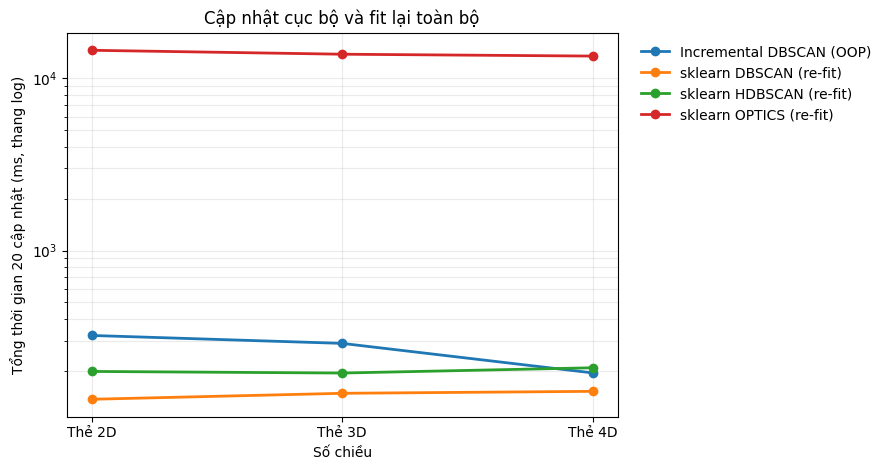

In [2]:
runtime = summary[["stream", "method", "update_total_median_ms", "update_total_std_ms"]].copy()
runtime["20 cập nhật (trung vị ± độ lệch chuẩn), ms"] = runtime.apply(
    lambda row: f"{row['update_total_median_ms']:.2f} ± {row['update_total_std_ms']:.2f}",
    axis=1,
)
display(
    runtime.pivot(
        index="stream",
        columns="method",
        values="20 cập nhật (trung vị ± độ lệch chuẩn), ms",
    ).reindex(columns=method_order)
)

fig, ax = plt.subplots(figsize=(9, 4.8))
for method in method_order:
    rows = summary[summary["method"] == method]
    ax.plot(
        rows["stream"].astype(str),
        rows["update_total_median_ms"],
        marker="o",
        linewidth=2,
        label=method,
    )
ax.set_yscale("log")
ax.set_ylabel("Tổng thời gian 20 cập nhật (ms, thang log)")
ax.set_xlabel("Số chiều")
ax.set_title("Cập nhật cục bộ và fit lại toàn bộ")
ax.grid(True, which="both", alpha=0.25)
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()


### Cách đọc thời gian

Trong prefix 20 cập nhật này, sklearn DBSCAN fit lại có tổng thời gian thấp hơn Incremental DBSCAN OOP ở cả 2D, 3D và 4D. HDBSCAN cũng nhanh hơn ở 2D và 3D; ở 4D, bản OOP thấp hơn một chút. OPTICS mất khoảng 13,5–14,6 giây cho 20 lần fit lại trong cấu hình này. Fit D0 ban đầu của bản OOP mất khoảng 1,29–1,43 giây, cao hơn nhiều so với DBSCAN sklearn (khoảng 7,8–9,4 ms). Kết quả này chỉ mô tả cấu hình và môi trường đã đo, chưa cho thấy lợi thế thời gian của bản OOP trên prefix 20 thao tác.



## 4. Chất lượng cụm: Silhouette tự cài

Bảng dưới tính trên **trạng thái cuối sau cùng 20 cập nhật** cho mỗi cấu hình 2D, 3D và 4D. Trong mỗi chiều, bốn thuật toán nhận cùng tập điểm cuối, cùng thứ tự cập nhật và cùng khoảng cách Euclidean. Bản Incremental DBSCAN được cập nhật từng bước; ba estimator sklearn được fit trên cùng tập điểm cuối.

Silhouette nằm trong `[-1, 1]`; giá trị cao hơn thường biểu thị cụm chặt hơn và tách nhau rõ hơn. Điểm noise (`-1`) bị loại khỏi phép tính, nên bảng báo thêm tỉ lệ noise và số cụm. Phép tính gọi hàm tự cài trong `src/evaluation/metrics.py`, không gọi sklearn Silhouette.

Điểm này được tính một lần trên trạng thái cuối xác định, không phải trung bình 5 lượt benchmark thời gian. Chỉ so các phương pháp trong cùng cấu hình số chiều; thay đổi số chiều làm thay đổi không gian và khoảng cách.


In [3]:
import numpy as np
from sklearn.cluster import DBSCAN as SklearnDBSCAN, HDBSCAN, OPTICS

from baseline.sklearn_dbscan import read_stream
from src.evaluation.metrics import silhouette_score as custom_silhouette_score
from src.experiments.engine import IncrementalEngine
from src.preprocessing.stream_scaling import stream_coordinates


def silhouette_or_nan(coords, labels):
    labels = np.asarray(labels)
    n_clusters = len(set(labels.tolist()) - {-1})
    n_scored = int(np.count_nonzero(labels != -1))
    if n_clusters < 2 or n_scored <= n_clusters:
        return np.nan
    return custom_silhouette_score(coords, labels)


stream_dir = ROOT / "data" / "raw" / "card_stream"
d0, updates, params, feature_cols = read_stream(stream_dir)
eps = float(params["eps"])
min_pts = int(params["minpts"])
updates20 = updates.sort_values("step").head(20).reset_index(drop=True)
coords0_all = stream_coordinates(params, d0, feature_cols)
coords_updates_all = stream_coordinates(params, updates20, feature_cols)

quality_rows = []
for dimensions in (2, 3, 4):
    coords0 = coords0_all[:, :dimensions]
    update_coords = coords_updates_all[:, :dimensions]
    incremental = IncrementalEngine(eps, min_pts).fit(coords0)
    stream_to_engine_id = {
        int(stream_id): int(engine_id)
        for stream_id, engine_id in zip(d0["point_id"], incremental.snapshot()["ids"])
    }

    for index, row in updates20.iterrows():
        stream_id = int(row["point_id"])
        if row["op"] == "insert":
            engine_id = incremental.insert(update_coords[index])
            stream_to_engine_id[stream_id] = int(engine_id)
        elif row["op"] == "delete":
            engine_id = stream_to_engine_id.pop(stream_id)
            incremental.delete(engine_id)
        else:
            raise ValueError(f"Op không hợp lệ: {row['op']}")

    final_state = incremental.snapshot()
    final_coords = final_state["coords"]
    labels_by_method = {
        "Incremental DBSCAN (OOP)": final_state["labels"],
        "sklearn DBSCAN (re-fit)": SklearnDBSCAN(
            eps=eps, min_samples=min_pts, metric="euclidean", n_jobs=1
        ).fit_predict(final_coords),
        "sklearn HDBSCAN (re-fit)": HDBSCAN(
            min_cluster_size=max(2, min_pts),
            min_samples=min_pts,
            metric="euclidean",
            cluster_selection_method="eom",
            n_jobs=1,
        ).fit_predict(final_coords),
        "sklearn OPTICS (re-fit)": OPTICS(
            min_samples=min_pts,
            max_eps=eps + 1e-6,
            metric="euclidean",
            cluster_method="dbscan",
            eps=eps,
            n_jobs=1,
        ).fit_predict(final_coords),
    }

    for method in method_order:
        labels = np.asarray(labels_by_method[method])
        quality_rows.append({
            "Cấu hình": f"Thẻ {dimensions}D",
            "Phương pháp": method,
            "Silhouette (tự cài, bỏ noise)": silhouette_or_nan(final_coords, labels),
            "Số cụm": len(set(labels.tolist()) - {-1}),
            "Tỉ lệ noise": float(np.mean(labels == -1)),
        })

quality = pd.DataFrame(quality_rows)
display(quality.round(4))


C:\Users\nguye\AppData\Roaming\Python\Python314\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\Users\nguye\AppData\Roaming\Python\Python314\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


C:\Users\nguye\AppData\Roaming\Python\Python314\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,Cấu hình,Phương pháp,"Silhouette (tự cài, bỏ noise)",Số cụm,Tỉ lệ noise
0,Thẻ 2D,Incremental DBSCAN (OOP),0.7785,3,0.01
1,Thẻ 2D,sklearn DBSCAN (re-fit),0.7785,3,0.01
2,Thẻ 2D,sklearn HDBSCAN (re-fit),0.7785,3,0.01
3,Thẻ 2D,sklearn OPTICS (re-fit),0.7785,3,0.01
4,Thẻ 3D,Incremental DBSCAN (OOP),0.7839,3,0.01
5,Thẻ 3D,sklearn DBSCAN (re-fit),0.7839,3,0.01
6,Thẻ 3D,sklearn HDBSCAN (re-fit),0.7839,3,0.01
7,Thẻ 3D,sklearn OPTICS (re-fit),0.7839,3,0.01
8,Thẻ 4D,Incremental DBSCAN (OOP),0.7463,3,0.01
9,Thẻ 4D,sklearn DBSCAN (re-fit),0.7463,3,0.01


Silhouette là chỉ số chất lượng chính trong notebook. Kết quả ở trên được tính sau cùng một prefix 20 cập nhật; nếu một cấu hình chỉ còn dưới hai cụm hợp lệ thì Silhouette không xác định (`NaN`). Tỉ lệ noise cần đọc cùng điểm Silhouette vì noise không nằm trong phép tính.

Các giá trị giữa 2D, 3D và 4D không nên xem như cùng điều kiện: mỗi cấu hình bổ sung đặc trưng và làm đổi khoảng cách. Bảng benchmark thời gian dùng năm lượt lặp; Silhouette ở đây mô tả một trạng thái cuối xác định, không phải số đo runtime.

## 5. Chi phí fit ban đầu

Thời gian cập nhật không kể chi phí fit D0. Bảng sau giúp tránh kết luận chỉ từ một phía:


In [4]:
fit = summary[["stream", "method", "initial_fit_median_ms"]].copy()
fit["Fit D0 (trung vị), ms"] = fit["initial_fit_median_ms"].map(lambda value: f"{value:.2f}")
display(fit.pivot(index="stream", columns="method", values="Fit D0 (trung vị), ms").reindex(columns=method_order))


method,Incremental DBSCAN (OOP),sklearn DBSCAN (re-fit),sklearn HDBSCAN (re-fit),sklearn OPTICS (re-fit)
stream,,,,
Thẻ 2D,1315.57,8.22,10.52,697.82
Thẻ 3D,1288.58,7.75,10.46,701.88
Thẻ 4D,1434.08,9.42,13.32,693.52


## 6. Kết luận trình bày

1. Bản OOP tự cài đặt DBSCAN và cập nhật cục bộ sau insert/delete.
2. Silhouette tự cài được dùng làm chỉ số chính để đọc chất lượng cụm; bảng kèm số cụm và tỉ lệ noise.
3. Scikit-learn DBSCAN là baseline **fit lại toàn bộ**, vì API scikit-learn không cung cấp Incremental DBSCAN/`partial_fit`.
4. HDBSCAN và OPTICS là các thuật toán mật độ khác dùng để đối chiếu Silhouette và thời gian; chúng không phải phiên bản incremental của DBSCAN.
5. Kết quả chỉ áp dụng cho D0 500 điểm, prefix 20 cập nhật, các đặc trưng và tham số đã công bố. Runtime được lặp 5 lần; Silhouette được tính một lần trên trạng thái cuối xác định. Chi tiết lượt chạy nằm trong `results/density_algorithm_benchmark_repeats.csv`; từng bước nằm trong `results/density_algorithm_benchmark_runs.csv`.

Để phát lại benchmark đầy đủ sau khi cập nhật code, chạy từ thư mục repo:

```bash
python -m baseline.benchmark_density_algorithms --repeats 5 --warmups 1 --max-steps 20 --seed 42
```
